# 20. Baseline ulang pada data Palm bersih
**Penelitian:** Deteksi anemia dari citra pucat (telapak tangan, kuku, konjungtiva) dengan data pooling multi-situs.

**Tujuan:** melatih ulang 12 algoritma klasik (Naive Bayes, k-NN, SVM dengan dua konfigurasi, Decision Tree, Random Forest, Logistic Regression, XGBoost, ANN, AdaBoost, LightGBM, CatBoost, Stacking; bersama AlexNet dan MobileNetV2 total 14 algoritma) pada data Palm bersih (citra identik dan pasangan berlabel bertentangan dibuang) untuk skema 70:10:20 dan 80:10:10. Augmentasi (rotasi 90, rotasi 270, flip vertikal, flip horizontal) hanya pada data latih setelah pembagian data. Hiperparameter k-NN, SVM, dan Decision Tree mengikuti Appiahene et al. (2023); validation set dipakai untuk membandingkan model, bukan untuk tuning.

**Masukan:** Dataset (Mendeley Data): Palm doi:10.17632/ccr8cm22vz.1, Nail doi:10.17632/2xx4j3kjg2.1, Conjunctiva doi:10.17632/nt7r8hv2pz.1. Letakkan dalam folder `Dataset_Multisite/{Palm,Nail,Conjunctiva}`.

**Keluaran (folder `hasil_revisi`):** `baseline_palm_data_bersih_computational_run.csv` (confusion matrix, akurasi, presisi, sensitivitas, spesifisitas, F1, AUC uji dan validasi, baseline kelas mayoritas).

**Kaitan dengan naskah:** Tabel II dan Supplementary Table S1. Nilai yang ditampilkan dalam draft tersedia sebagai tabel tersendiri di `results/csv/table_ii_selected_baselines.csv` dan `supplementary/Supplementary_Table_S1_Full_Baseline.csv`.

**Cara menjalankan:** Colab, Runtime > Run all. CPU sudah cukup; GPU tidak diperlukan. Seed acak = 42 dan urutan file diurutkan (`sorted`) sehingga hasil dapat direproduksi pada versi pustaka yang dicetak di sel kedua.

**Catatan sinkronisasi naskah (9 November 2026):** hasil Notebook 20 yang sebelumnya tersimpan merupakan snapshot komputasi. Nilai Stacking Ensemble pada snapshot tersebut berbeda dari nilai yang dilaporkan dalam draft final. Karena itu, menjalankan ulang notebook menulis ke `baseline_palm_data_bersih_computational_run.csv` dan tidak menimpa tabel manuscript-aligned. Jangan mengganti angka dalam tabel paper dengan snapshot ini tanpa memverifikasi run yang menjadi sumber draft.


In [1]:
!pip install xgboost lightgbm catboost -q

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


In [3]:
# ===== FUNGSI BERSAMA (identik di keempat notebook) =====
import os, re, hashlib, warnings
import numpy as np, pandas as pd, cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')

# ---------- KONFIGURASI (ubah hanya bagian ini) ----------
SEED = 42
BASE = '/content/drive/MyDrive/Dataset_Multisite'   # folder berisi subfolder Palm/, Nail/, Conjunctiva/
OUT  = '/content/drive/MyDrive/hasil_revisi'          # folder keluaran (CSV)
SITES = {'Palm': 0, 'Nail': 1, 'Conjunctiva': 2}
# Filter piksel memeriksa kanal L, R, dan G. Kanal B ikut difilter jika True
# (Appiahene et al. 2023 menuliskan kondisi min < R=G=B < max).
FILTER_INCLUDE_B = False
# True: buang juga citra bernama varian dari citra lain (akhiran FV/RA atau spasi+angka) yang citra dasarnya ada.
BUANG_VARIAN = True
os.makedirs(OUT, exist_ok=True)

# ---------- DAFTAR FILE ----------
def parse_label(name):
    """Label dari awalan nama file (Anemic / Non-Anemic); nama yang mengandung tanda kurung (salinan bernomor) dan awalan tidak dikenali dilewati."""
    if '(' in name: return None
    c = name.lower().replace(' ', '')
    if c.startswith('non-anemic'): return 0
    if c.startswith('anemic'): return 1
    return None

def list_used_files():
    rows = []
    for site, sid in SITES.items():
        d = os.path.join(BASE, site)
        for n in sorted(os.listdir(d)):          # sorted -> urutan deterministik
            lab = parse_label(n)
            if lab is not None:
                rows.append(dict(site=site, site_id=sid, file=n, path=os.path.join(d, n), label=lab))
    return pd.DataFrame(rows)

def md5(path):
    with open(path, 'rb') as f: return hashlib.md5(f.read()).hexdigest()

# ---------- EKSTRAKSI FITUR ----------
def feat_original(img, lo=50, hi=200):
    """Fitur [mean a*, mean b*, mean G] dengan filter piksel. Return (fitur, mask_kosong)."""
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab); R, G, B = cv2.split(rgb)
    m = (L > lo) & (L < hi) & (R > lo) & (R < hi) & (G > lo) & (G < hi)
    if FILTER_INCLUDE_B: m &= (B > lo) & (B < hi)
    if m.any(): return [a[m].mean(), b[m].mean(), G[m].mean()], False
    return [0.0, 0.0, 0.0], True

def feat_otsu(img):
    """Fitur dari piksel foreground Otsu (grayscale). Tanpa filter L/R/G. Return (fitur, mask_kosong)."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mk = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = mk > 0
    if not m.any(): return [0.0, 0.0, 0.0], True
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    _, a, b = cv2.split(lab); G = rgb[:, :, 1]
    return [a[m].mean(), b[m].mean(), G[m].mean()], False

# ---------- PEMBAGIAN DATA & EVALUASI ----------
def split_idx(y, scheme, seed=SEED):
    """Return (train, val, test) berupa indeks. Skema: '80:20', '80:10:10', '70:10:20'."""
    idx = np.arange(len(y))
    if scheme == '80:20':
        tr, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        return tr, None, te
    if scheme == '80:10:10':
        tr, tmp = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=seed)
        return tr, va, te
    if scheme == '70:10:20':
        trva, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        tr, va = train_test_split(trva, test_size=0.125, stratify=y[trva], random_state=seed)
        return tr, va, te
    raise ValueError(scheme)

def metrics_from(yte, pred, proba):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(yte), 'TP+TN+FP+FN harus sama dengan jumlah data uji'
    two = len(set(yte)) == 2
    return dict(n_test=len(yte), n_test_anemic=int((yte == 1).sum()), TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
                acc=100*(tp+tn)/len(yte),
                sens=100*tp/(tp+fn) if tp+fn else np.nan,
                spec=100*tn/(tn+fp) if tn+fp else np.nan,
                f1=100*f1_score(yte, pred, zero_division=0),
                auc=100*roc_auc_score(yte, proba) if two else np.nan,
                baseline_mayoritas=100*max((yte == 1).mean(), (yte == 0).mean()))

def fit_lgbm(Xtr, ytr):
    sc = StandardScaler().fit(Xtr)
    m = LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1).fit(sc.transform(Xtr), ytr)
    return sc, m

def predict_lgbm(sc, m, X):
    proba = m.predict_proba(sc.transform(X))[:, 1]
    return (proba >= 0.5).astype(int), proba

def bersihkan(df):
    """Buang salinan identik (MD5; simpan satu) dan KEDUA file bila citra identik berlabel berbeda."""
    df = df.copy(); df['md5'] = df['path'].map(md5)
    konflik = df.groupby('md5').label.transform('nunique') > 1
    salinan = df.duplicated('md5', keep='first')
    out = df[~(konflik | salinan)].reset_index(drop=True)
    if BUANG_VARIAN:
        out = out.drop(index=sorted({a for a, b in pasangan_varian(out)})).reset_index(drop=True)
    return out

def cek_kebocoran(md5s, tr, va, te, wajib=True):
    """Pemeriksaan kebocoran: indeks latih/validasi/uji harus saling lepas dan tidak ada citra identik (MD5) lintas partisi.
    Return jumlah citra identik lintas partisi, mis. {'latih-uji': 0}. wajib=True -> hentikan program bila ada pelanggaran."""
    parts = {'latih': set(tr), 'uji': set(te)}
    if va is not None: parts['val'] = set(va)
    nm = sorted(parts)
    for i, a in enumerate(nm):
        for b in nm[i + 1:]:
            assert not (parts[a] & parts[b]), f'Indeks tumpang tindih: {a}-{b}'
    m = {k: set(np.asarray(md5s)[sorted(v)]) for k, v in parts.items()}
    bocor = {f'{a}-{b}': len(m[a] & m[b]) for i, a in enumerate(nm) for b in nm[i + 1:]}
    if wajib: assert all(v == 0 for v in bocor.values()), f'Citra identik lintas partisi: {bocor}'
    return bocor

def pasangan_varian(df):
    """Pasangan (indeks varian, indeks citra dasar) pada df (indeks posisi 0..n-1): nama berakhiran FV/RA atau spasi+angka
    yang nama dasarnya ada pada situs yang sama (mis. Anemic-001FV dengan Anemic-001)."""
    stem = df.file.str.replace(r'\.[A-Za-z]+$', '', regex=True)
    base = stem.str.replace(r'\s\d+$', '', regex=True).str.replace(r'(FV|RA)$', '', regex=True)
    key = {(s, t): i for i, (s, t) in enumerate(zip(df.site, stem))}
    return [(i, key[(s, b)]) for i, (s, t, b) in enumerate(zip(df.site, stem, base)) if b != t and (s, b) in key]

def cek_varian(pasangan, tr, va, te):
    """Jumlah pasangan varian-dasar yang terpisah di partisi berbeda (informasi; idealnya 0)."""
    part = {}
    for ids, nm in [(tr, 'latih'), (va, 'val'), (te, 'uji')]:
        if ids is not None:
            for i in ids: part[i] = nm
    return sum(1 for a, b in pasangan if a in part and b in part and part[a] != part[b])

In [4]:
import sys, numpy, pandas, cv2, sklearn, lightgbm
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| OpenCV', cv2.__version__, '| scikit-learn', sklearn.__version__, '| LightGBM', lightgbm.__version__, '| SEED', SEED)

Python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | OpenCV 4.14.0 | scikit-learn 1.6.1 | LightGBM 4.6.0 | SEED 42


In [5]:
# ===== BASELINE ULANG PADA DATA PALM BERSIH: 12 algoritma klasik (11 sebelumnya + Decision Tree dari [1]); AlexNet dan MobileNetV2 dijalankan terpisah =====
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

AUGMENT = True                       # True: 5 versi per citra LATIH (asli, rot90, rot270, flip vertikal, flip horizontal)
SCHEMES = ['70:10:20', '80:10:10']

palm = bersihkan(list_used_files()); palm = palm[palm.site == 'Palm'].reset_index(drop=True)
y = palm.label.to_numpy(); imgs = [cv2.imread(p) for p in palm.path]
VERS = [lambda im: im,
        lambda im: cv2.rotate(im, cv2.ROTATE_90_CLOCKWISE),
        lambda im: cv2.rotate(im, cv2.ROTATE_90_COUNTERCLOCKWISE),
        lambda im: cv2.flip(im, 0),
        lambda im: cv2.flip(im, 1)]
FA = np.array([[feat_original(v(im))[0] for v in VERS] for im in imgs])        # bentuk (n, 5, 3)
print('Citra Palm bersih:', len(y), '| anemic:', int(y.sum()), '| non-anemic:', int((y == 0).sum()))
print('Selisih maksimum fitur citra asli vs hasil rotasi/flip (0 = identik):', float(np.abs(FA - FA[:, :1, :]).max()))

def make_models(Xtr, ytr, grp):
    # CV internal Stacking dikelompokkan per citra agar salinan augmentasi tidak terpisah antar lipatan
    cv = list(GroupKFold(n_splits=5).split(Xtr, ytr, grp))
    est = [('rf', RandomForestClassifier(n_estimators=100, min_samples_leaf=10, random_state=SEED)),
           ('xgb', XGBClassifier(n_estimators=100, random_state=SEED)),
           ('svm', SVC(kernel='sigmoid', C=100, max_iter=5000, coef0=0.1, probability=True, random_state=SEED))]
    return {
        'Naive Bayes': GaussianNB(),
        'k-NN (k=100, Euclidean)': KNeighborsClassifier(n_neighbors=100, metric='euclidean'),
        'SVM (sigmoid, C=100, max_iter=5000, coef0=0,1)': SVC(kernel='sigmoid', C=100, max_iter=5000, coef0=0.1, random_state=SEED),
        'SVM (parameter [1]: sigmoid, C=100, max_iter=100, tol=0,1)': SVC(kernel='sigmoid', C=100, max_iter=100, tol=0.1, random_state=SEED),
        'Decision Tree (parameter [1]: leaf>=10, split>=5)': DecisionTreeClassifier(min_samples_leaf=10, min_samples_split=5, random_state=SEED),
        'Random Forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=10, random_state=SEED),
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=SEED),
        'XGBoost': XGBClassifier(n_estimators=100, random_state=SEED),
        'ANN (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=2000, random_state=SEED),
        'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=SEED),
        'LightGBM': LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1),
        'CatBoost': CatBoostClassifier(n_estimators=100, random_state=SEED, verbose=0),
        'Stacking Ensemble': StackingClassifier(estimators=est, final_estimator=LogisticRegression(), cv=cv)}

def score_of(model, X):
    # SVC: skor keputusan (decision_function) untuk AUC; probabilitas Platt dapat tidak konsisten dengan prediksi
    return model.decision_function(X) if isinstance(model, SVC) else model.predict_proba(X)[:, 1]

rows = []
for scheme in SCHEMES:
    tr, va, te = split_idx(y, scheme)
    vlin = cek_varian(pasangan_varian(palm), tr, va, te)
    bocor = cek_kebocoran(palm.md5.to_numpy(), tr, va, te)          # indeks lepas dan tidak ada citra identik lintas partisi
    Xtr = FA[tr] if AUGMENT else FA[tr][:, :1, :]
    k = Xtr.shape[1]
    Xtr = Xtr.reshape(-1, 3); ytr = np.repeat(y[tr], k); grp = np.repeat(tr, k)
    assert not (set(grp) & set(te)) and not (set(grp) & set(va)), 'Salinan augmentasi citra uji/validasi masuk ke data latih'
    sc = StandardScaler().fit(Xtr)                       # scaler hanya dari data latih
    Xtr_s, Xva_s, Xte_s = sc.transform(Xtr), sc.transform(FA[va][:, 0, :]), sc.transform(FA[te][:, 0, :])
    yva, yte = y[va], y[te]
    print(f'\nSkema {scheme}: pemeriksaan kebocoran lolos {bocor}, pasangan varian lintas partisi={vlin}; baris latih={len(ytr)} (citra latih={len(tr)}), validasi={len(yva)}, uji={len(yte)}')
    for name, mdl in make_models(Xtr_s, ytr, grp).items():
        mdl.fit(Xtr_s, ytr)
        r = metrics_from(yte, mdl.predict(Xte_s), score_of(mdl, Xte_s))
        v = metrics_from(yva, mdl.predict(Xva_s), score_of(mdl, Xva_s))
        prec = 100 * r['TP'] / (r['TP'] + r['FP']) if (r['TP'] + r['FP']) else np.nan
        rows.append(dict(skema=scheme, algoritma=name, n_latih_baris=len(ytr), n_val=len(yva), **r, precision=prec, val_acc=v['acc'], val_auc=v['auc']))
hasil = pd.DataFrame(rows)
kolom = ['skema','algoritma','n_latih_baris','n_val','n_test','n_test_anemic','TP','TN','FP','FN','acc','precision','sens','spec','f1','auc','val_acc','val_auc','baseline_mayoritas']
hasil = hasil[kolom].round(2)
hasil.to_csv(os.path.join(OUT, 'baseline_palm_data_bersih_computational_run.csv'), index=False)
for scheme in SCHEMES:
    h = hasil[hasil.skema == scheme].sort_values('acc', ascending=False)
    print(f'\n=== Skema {scheme} (urut akurasi uji) ===')
    print(h[['algoritma','acc','precision','sens','spec','f1','auc','val_acc','val_auc','baseline_mayoritas']].to_string(index=False))
    print('Model terbaik menurut AUC validasi:', h.sort_values('val_auc', ascending=False).iloc[0]['algoritma'])

Citra Palm bersih: 519 | anemic: 301 | non-anemic: 218
Selisih maksimum fitur citra asli vs hasil rotasi/flip (0 = identik): 0.0

Skema 70:10:20: pemeriksaan kebocoran lolos {'latih-uji': 0, 'latih-val': 0, 'uji-val': 0}, pasangan varian lintas partisi=0; baris latih=1815 (citra latih=363), validasi=52, uji=104

Skema 80:10:10: pemeriksaan kebocoran lolos {'latih-uji': 0, 'latih-val': 0, 'uji-val': 0}, pasangan varian lintas partisi=0; baris latih=2075 (citra latih=415), validasi=52, uji=52

=== Skema 70:10:20 (urut akurasi uji) ===
                                                 algoritma   acc  precision  sens  spec    f1   auc  val_acc  val_auc  baseline_mayoritas
                                                  CatBoost 73.08      78.57 73.33 72.73 75.86 76.82    67.31    79.85               57.69
                                                   XGBoost 71.15      75.86 73.33 68.18 74.58 74.77    69.23    76.21               57.69
                                         Stacki

In [6]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = '/content/drive/MyDrive/hasil_revisi'          # folder berisi CSV hasil
LABEL = ['Non-anemic', 'Anemic']

def cm_dari_baris(r):
    """Matriks [[TN, FP], [FN, TP]]: baris = kelas sebenarnya, kolom = prediksi."""
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], dtype=int)
    n = r['n_test'] if 'n_test' in r.index else r['n']
    assert cm.sum() == n, f'TP+TN+FP+FN ({cm.sum()}) harus sama dengan jumlah data ({n})'
    return cm

def gambar_cm(cm, judul, ax):
    pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) * 100      # persen per kelas sebenarnya
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.1f}%)', ha='center', va='center', fontsize=9,
                    color='white' if pct[i, j] > 50 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(LABEL, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(LABEL, fontsize=8)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title(judul, fontsize=8)

def grid_cm(df, judul, ncol=4, simpan=None, judul_utama=''):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.4 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axs.ravel(), df.iterrows()):
        ax.axis('on'); gambar_cm(cm_dari_baris(r), judul(r), ax)
    fig.suptitle(judul_utama); plt.tight_layout()
    if simpan: plt.savefig(os.path.join(OUT, simpan), dpi=150)
    plt.show()

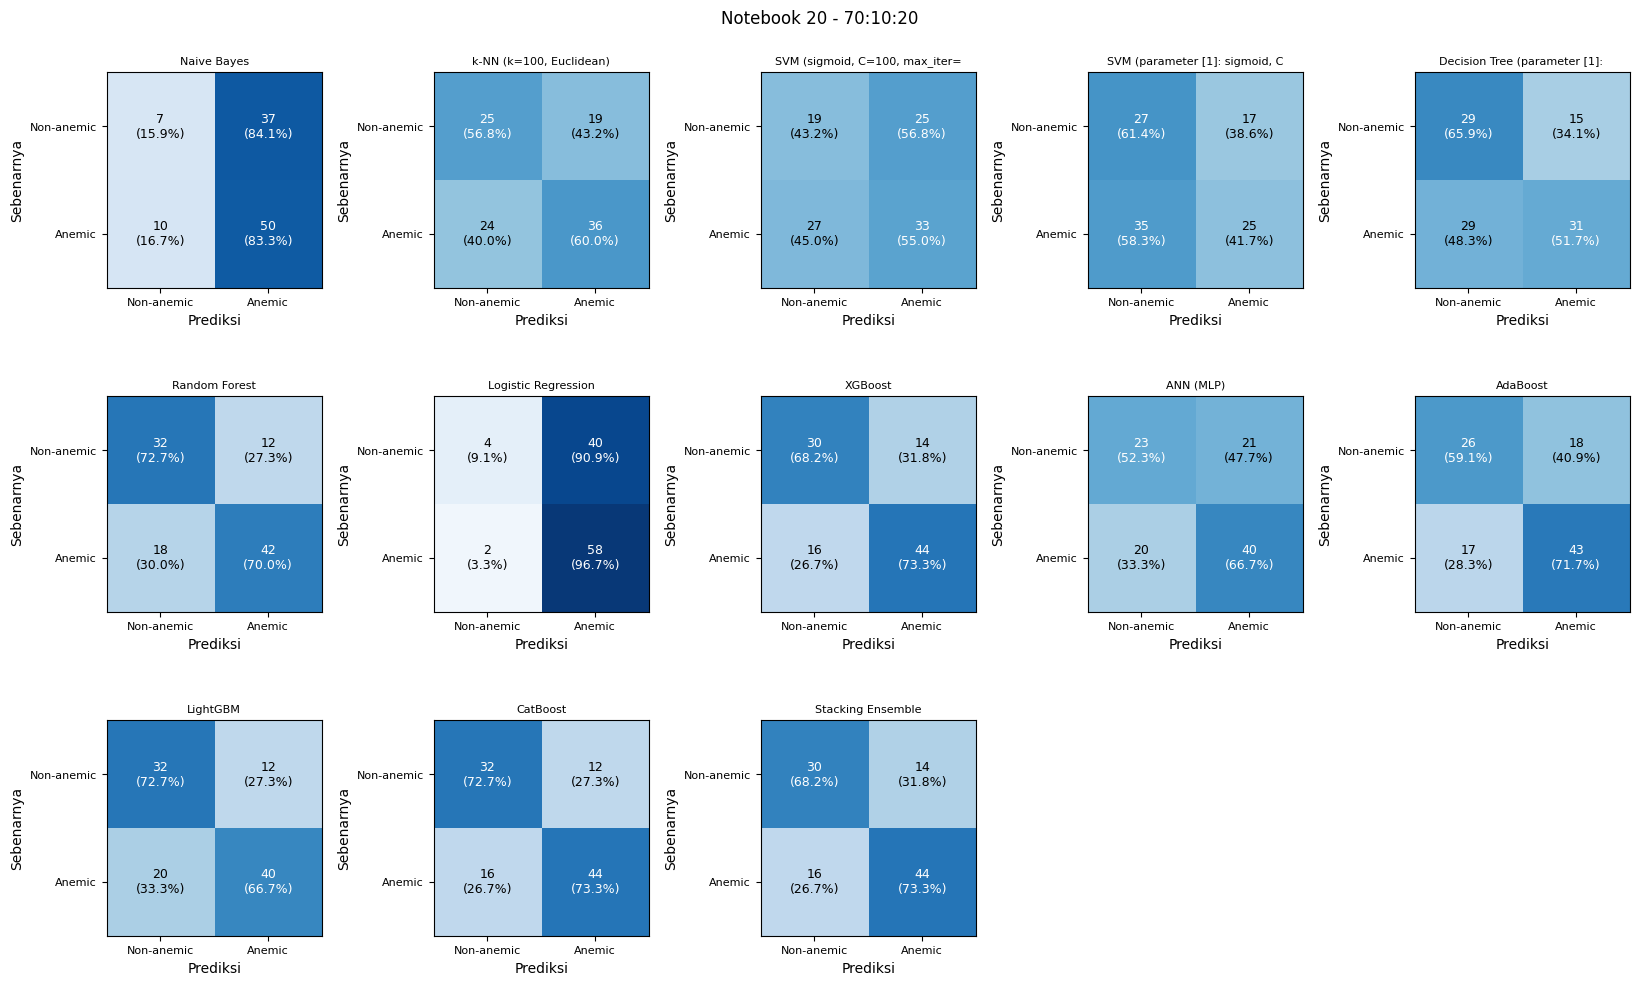

In [7]:
b = pd.read_csv(f'{OUT}/baseline_palm_data_bersih.csv')
d = b[b.skema == '70:10:20']                                                   # atau '80:10:10'
grid_cm(d, lambda r: r['algoritma'][:30], ncol=5, simpan='cm_nb20_70_10_20.png', judul_utama='Notebook 20 - 70:10:20')